# Fig. 7: formation energy against the Fermi level

This notebook reproduces Fig. 7 of the DefectNet paper: the formation energies of the benchmark defects in
CdSe$_{0.06}$Te$_{0.94}$, Ag$_2$CdGeS$_4$ in ordering II and CuGaSeTe in ordering II against the Fermi level, from DFT
(solid) and DefectNet (dashed), on the HSE06 band edges, with the self-consistent Fermi level at 300 K. It draws
the three panels from the DFT data and the paper's DefectNet energies, then repeats the DefectNet relaxations of
CdSe$_{0.06}$Te$_{0.94}$ and draws panel (a) again from them.

Open this notebook from the `examples/paper/` folder of the repository. The DFT data it needs are in `data/` as
Apache Arrow tables (see `README.md` in this folder for the columns), and the model is the `DefectNet-v1.0.pt` weights file
of the v1.0 release. A GPU is strongly recommended.

## Install and download the model

The cell below installs TACE at commit `057e463` with the patch in `patches/`, the DefectNet package and `pyarrow`,
skipping every step that is already done. Install PyTorch for your machine first (pytorch.org). The weights
(`DefectNet-v1.0.pt`, 891 MB) are downloaded with the GitHub command-line tool unless a copy is already here or in
`examples/`.

In [1]:
%%bash
cd ../..                                         # repository root
if python -c "import tace" 2>/dev/null; then echo "TACE is already installed"
else
  git clone -q https://github.com/xvzemin/tace.git ../tace
  git -C ../tace checkout -q 057e463
  git -C ../tace apply "$PWD/patches/tace-057e463.patch"
  pip install -q -e ../tace
fi
python -c "import defectnet" 2>/dev/null && echo "DefectNet is already installed" || pip install -q -e .
python -c "import pyarrow" 2>/dev/null && echo "pyarrow is already installed" || pip install -q pyarrow
cd examples/paper
if [ -f DefectNet-v1.0.pt ]; then echo "DefectNet-v1.0.pt is already here"
elif [ -f ../DefectNet-v1.0.pt ]; then ln -s ../DefectNet-v1.0.pt . && echo "using ../DefectNet-v1.0.pt"
else gh release download v1.0 -R msehabibur/DefectNet -p DefectNet-v1.0.pt; fi

TACE is already installed


DefectNet is already installed


pyarrow is already installed


DefectNet-v1.0.pt is already here


## Load the model and the data

Every row of an Arrow table is one DFT calculation. `atoms(row)` builds the ASE structure the benchmark started from
(the DFT input geometry of a defect cell, the DFT final geometry of a pristine cell), and `seed(row)` is the random
seed of its rattle, the CRC32 checksum of the row's `path`, so a relaxation here starts from exactly the same
displaced atoms as in the paper. GPU arithmetic is not bit-for-bit reproducible across devices, so energies can
differ from the paper values by a few meV.

In [2]:
import logging
import warnings
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)                 # hides TACE's start-up notes

import zlib
import numpy as np
import matplotlib.pyplot as plt
import pyarrow.feather as feather
from ase import Atoms

import defectnet as dn


def table(name):
    return feather.read_table(f"data/{name}.arrow").to_pylist()


def atoms(row, positions="start_positions"):
    return Atoms(row["start_symbols"], positions=row[positions], cell=row["start_cell"], pbc=True)


def seed(row):
    return zlib.crc32(row["path"].encode())


calc = dn.load("DefectNet-v1.0.pt", functional="PBEsol")
cells = table("fig7_cells")
pristine = {r["path"]: r for r in table("pristine_pbesol")}
print(len(cells), "defect cells and", len(pristine), "pristine cells, PBEsol")

52 defect cells and 15 pristine cells, PBEsol


## Chemical potentials and HSE06 band edges

`fig7_compounds.arrow` holds every chemical-potential limit of the three semiconductors (the dopant elements at the
caps of the same limit), the HSE06 VBM and gap of each, and marks the limit drawn in the paper (`shown`): the one at
which the lowest formation energy at midgap is highest. The PBEsol energies are placed on the HSE06 band edges by
shifting the VBM. The DFT energies use the DFT chemical potentials of the limit (`mu_values`) and the DefectNet
energies the DefectNet chemical potentials of the same limit on the DefectNet hull (`mu_defectnet`). With the Fermi
level $E_F$ measured from the HSE06 VBM,

$$E^{f}(q, E_F) = E_{def}(q) - E_{bulk} - \sum_i n_i \mu_i + q\,(E_{VBM}^{HSE} + E_F).$$

In [3]:
import re

limits = table("fig7_compounds")
shown = {v["host"]: v for v in limits if v["shown"]}
for h, v in shown.items():
    print(f"{h:24s} {v['label']:20s} HSE06 VBM {v['vbm_hse']:.4f} eV, gap {v['gap_hse']:.4f} eV")


def ef_line(r, e_def, e_bulk, v, mu):
    # E_f at E_F = 0 on the HSE06 axis for one charge state
    mu = dict(zip(v["mu_elements"], v[mu]))
    change = dict(zip(r["change_elements"], r["change_counts"]))
    return dn.formation_energy(e_def, e_bulk, change, mu, r["q"], v["vbm_hse"])


def energies(h, e_cell, e_bulk, mu="mu_values"):
    # {defect: {q: E_f(q, E_F = 0)}} for the cells of h
    out = {}
    for r in cells:
        if r["host"] == h:
            out.setdefault(r["defect"], {})[r["q"]] = ef_line(r, e_cell(r), e_bulk(r), shown[h], mu)
    return out

CdSe0.06Te0.94           Te-rich / Cd-poor    HSE06 VBM 1.7118 eV, gap 1.4045 eV
Ag2Cd1Ge1S4_stannite     Ag-rich / Cd-poor    HSE06 VBM 3.0429 eV, gap 1.6079 eV
Cu1Ga1Se1Te1_stannite    Cu-rich / Ga-poor    HSE06 VBM 4.3246 eV, gap 0.6428 eV


## Self-consistent Fermi level

The Fermi level $E_F^{sc}$ is where the net charge vanishes,

$$\sum_{d,q} q\,N_{d}\,e^{-E^{f}_{d}(q, E_F)/k_BT} + p(E_F) - n(E_F) = 0,$$

with $N_d$ the density of the lattice site the defect replaces (formula units for an interstitial), $T$ = 300 K,
and the free carriers from Fermi–Dirac integrals with effective densities of states $N_c = N_v = 2.5\times10^{19}$
cm$^{-3}$:

$$p = N_v F_{1/2}(-E_F/k_BT), \qquad n = N_c F_{1/2}\big((E_F - E_g)/k_BT\big).$$

In [4]:
from scipy.integrate import quad
from scipy.optimize import brentq

KT, NCV = 8.617333e-5 * 300, 2.5e19


def f12(eta):
    return 2 / np.sqrt(np.pi) * quad(lambda t: np.sqrt(t) / (1 + np.exp(np.clip(t - eta, -700, 700))), 0, np.inf)[0]


def site_density(h):
    # {defect: N_d in cm^-3}
    P = next(pristine[r["pristine"]] for r in cells if r["host"] == h)
    count = {e: P["start_symbols"].count(e) for e in set(P["start_symbols"])}
    fu = len(P["start_symbols"]) / sum(float(n or 1) for n in re.findall(r"[A-Z][a-z]?([\d.]*)", h.split("_")[0]))
    out = {}
    for r in cells:
        if r["host"] == h:
            removed = [count[e] for e, n in zip(r["change_elements"], r["change_counts"]) if n < 0]
            out[r["defect"]] = (min(removed) if removed else fu) / (shown[h]["volume_A3"] * 1e-24)
    return out


def fermi_sc(F, gap, nsite):
    def net(e):
        c = sum(q * nsite[d] * np.exp(-(f + q * e) / KT) for d in F for q, f in F[d].items())
        return c + NCV * f12(-e / KT) - NCV * f12((e - gap) / KT)
    return brentq(net, -1.0, gap + 1.0, xtol=1e-5)

## The three panels

For each defect the line is the lowest charge state at each Fermi level, $\min_q E^{f}(q, E_F)$, and the open
circles are the transition levels where the lowest charge state changes. The DefectNet energies are those of the
paper (columns `E_defectnet_paper`), with the DefectNet chemical potentials.

CdSe0.06Te0.94           14 charge states, RMSE 0.37 eV, E_F,sc 0.70 / 0.70 eV (paper: RMSE 0.37, E_F,sc 0.70 / 0.70 eV)
Ag2Cd1Ge1S4_stannite     18 charge states, RMSE 0.51 eV, E_F,sc 0.70 / 0.77 eV (paper: RMSE 0.51, E_F,sc 0.70 / 0.77 eV)


Cu1Ga1Se1Te1_stannite    20 charge states, RMSE 0.27 eV, E_F,sc 0.52 / 0.56 eV (paper: RMSE 0.27, E_F,sc 0.52 / 0.56 eV)


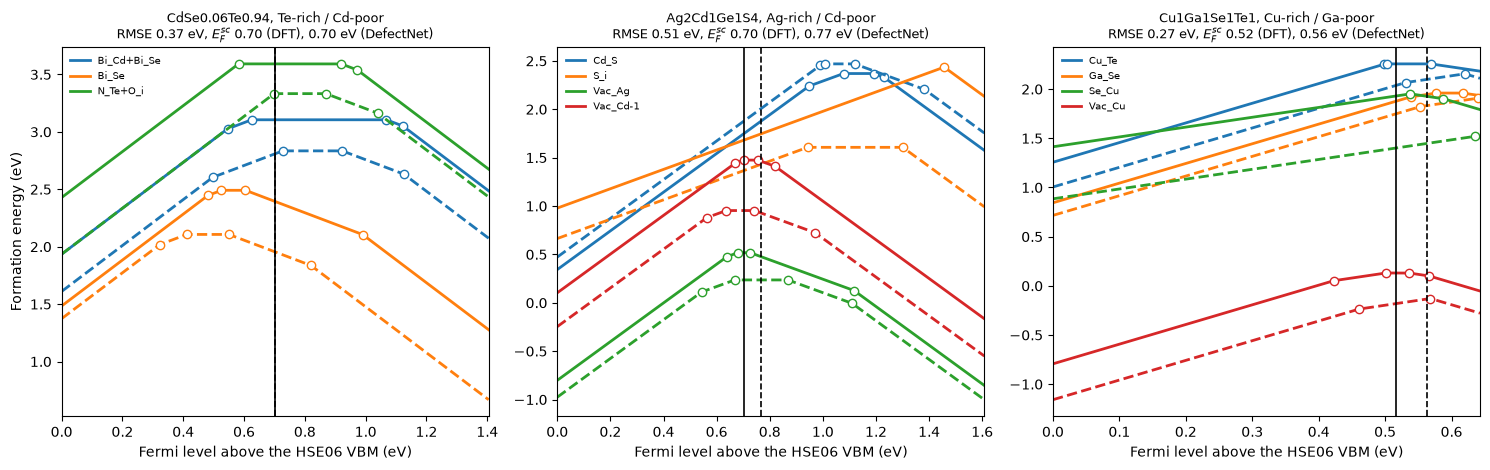

In [5]:
PAL = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
PAPER = {"CdSe0.06Te0.94": (0.37, 0.70, 0.70), "Ag2Cd1Ge1S4_stannite": (0.51, 0.70, 0.77), "Cu1Ga1Se1Te1_stannite": (0.27, 0.52, 0.56)}
rmse = lambda v: float(np.sqrt(np.mean(np.square(v))))


def panel(ax, h, F_dft, F_dn):
    gap = shown[h]["gap_hse"]
    ns = site_density(h)
    for (d, f), col in zip(sorted(F_dft.items()), PAL):
        for F, ls in ((f, "-"), (F_dn[d], "--")):
            xg, env = dn.fermi_grid(F, gap)
            ax.plot(xg, env, color=col, ls=ls, lw=2, label=d if ls == "-" else None)
            for e, q1, _ in dn.transition_levels(F, gap):
                ax.plot(e, F[q1] + q1 * e, "o", ms=6, mfc="white", mec=col)
    sc = fermi_sc(F_dft, gap, ns), fermi_sc(F_dn, gap, ns)
    for e, ls in zip(sc, ("-", "--")):
        ax.axvline(e, color="k", ls=ls, lw=1.2)
    err = [F_dn[d][q] - F_dft[d][q] for d in F_dft for q in F_dft[d]]
    ax.set_xlim(0, gap)
    ax.set_xlabel("Fermi level above the HSE06 VBM (eV)")
    ax.set_title(f"{h.split('_')[0]}, {shown[h]['label']}\nRMSE {rmse(err):.2f} eV, "
                 f"$E_F^{{sc}}$ {sc[0]:.2f} (DFT), {sc[1]:.2f} eV (DefectNet)", fontsize=9)
    ax.legend(frameon=False, fontsize=7)
    return len(err), rmse(err), sc


e_bulk = lambda key: (lambda r: pristine[r["pristine"]][key])
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, h in zip(axs, shown):
    F_dft = energies(h, lambda r: r["E_dft"], e_bulk("E_dft"))
    F_dn = energies(h, lambda r: r["E_defectnet_paper"], e_bulk("E_defectnet_paper"), "mu_defectnet")
    n, e, sc = panel(ax, h, F_dft, F_dn)
    print(f"{h:24s} {n} charge states, RMSE {e:.2f} eV, E_F,sc {sc[0]:.2f} / {sc[1]:.2f} eV "
          f"(paper: RMSE {PAPER[h][0]:.2f}, E_F,sc {PAPER[h][1]:.2f} / {PAPER[h][2]:.2f} eV)")
axs[0].set_ylabel("Formation energy (eV)")
plt.tight_layout()
plt.show()

## Worked example: DefectNet relaxations for CdSe$_{0.06}$Te$_{0.94}$

The pristine cell and the 14 charge states of panel (a) are relaxed from the same rattled starts as in the paper
(FIRE at a fixed cell to 0.02 eV/Å). This takes about ten minutes on one GPU.

Bi_Cd+Bi_Se  q = +1   DefectNet energy   -598.710 eV (paper   -598.710 eV)
Bi_Cd+Bi_Se  q = +2   DefectNet energy   -600.918 eV (paper   -600.918 eV)
Bi_Cd+Bi_Se  q = -1   DefectNet energy   -593.636 eV (paper   -593.636 eV)
Bi_Cd+Bi_Se  q = -2   DefectNet energy   -590.799 eV (paper   -590.799 eV)
Bi_Cd+Bi_Se  q = +0   DefectNet energy   -596.271 eV (paper   -596.271 eV)
N_Te+O_i     q = +2   DefectNet energy   -609.027 eV (paper   -609.027 eV)
N_Te+O_i     q = -1   DefectNet energy   -601.624 eV (paper   -601.624 eV)
N_Te+O_i     q = -2   DefectNet energy   -598.873 eV (paper   -598.873 eV)
N_Te+O_i     q = +0   DefectNet energy   -604.205 eV (paper   -604.205 eV)
Bi_Se        q = +1   DefectNet energy   -596.290 eV (paper   -596.290 eV)
Bi_Se        q = +2   DefectNet energy   -598.323 eV (paper   -598.323 eV)
Bi_Se        q = -1   DefectNet energy   -591.905 eV (paper   -591.905 eV)
Bi_Se        q = -2   DefectNet energy   -589.373 eV (paper   -589.373 eV)
Bi_Se        q = +0   Def

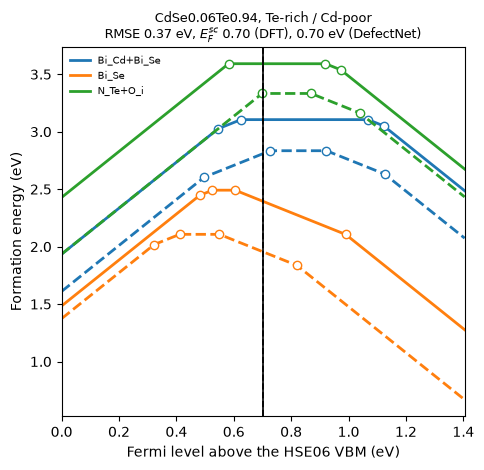

In [6]:
h = "CdSe0.06Te0.94"
mine = [r for r in cells if r["host"] == h]
P = pristine[mine[0]["pristine"]]
E_new = {P["path"]: dn.relax(atoms(P), calc, q=0, seed=seed(P)).info["energy"]}
for r in mine:
    E_new[r["path"]] = dn.relax(atoms(r), calc, q=r["q"], seed=seed(r)).info["energy"]
for r in mine:
    print(f"{r['defect']:12s} q = {r['q']:+d}   DefectNet energy {E_new[r['path']]:10.3f} eV (paper {r['E_defectnet_paper']:10.3f} eV)")

F_dft = energies(h, lambda r: r["E_dft"], e_bulk("E_dft"))
F_new = energies(h, lambda r: E_new[r["path"]], lambda r: E_new[r["pristine"]], "mu_defectnet")
fig, ax = plt.subplots(figsize=(5.2, 4.8))
n, e, sc = panel(ax, h, F_dft, F_new)
ax.set_ylabel("Formation energy (eV)")
print(f"this run: {n} charge states, RMSE {e:.2f} eV, E_F,sc {sc[0]:.2f} / {sc[1]:.2f} eV (paper: 0.37 eV, 0.70 / 0.70 eV)")
plt.show()